# Word Embeddings and NLP Sequence Modelling
## From text representation to IMDB sentiment classification

### objectives
By the end of this notebook, you should be able to:
1. Explain why raw text must be represented numerically.
2. Distinguish tokenization, token IDs, One-hot, Bag of Words, TF-IDF and embeddings.
3. Explain Word2Vec (CBOW and Skip-gram), GloVe, and static vs contextual embeddings.
4. Understand how a trainable Keras Embedding layer learns vectors.
5. Prepare IMDB reviews for sequence modelling.
6. Compare SimpleRNN, LSTM and Bidirectional LSTM on the same sentiment task.

### The learning path

```text
Raw text → Tokenization → Token IDs → Embeddings
         → RNN / LSTM / BiLSTM → Sentiment prediction
```

We have already studied recurrent networks and their gates. This notebook fills the missing bridge: **how text becomes numerical input for those networks**.

The IMDB comparison is an application of the concepts, not a claim that BiLSTM must always win.

# Part 1 – Why must text be represented numerically?

A neural network operates on numerical tensors. It cannot directly consume the meaning of a sentence as a human does.

Consider:

```text
The movie was excellent!
```

**Tokenization** breaks text into units called tokens. Depending on the tokenizer, a token can be a word, subword or punctuation mark.

A simple word tokenizer might produce:

```python
["The", "movie", "was", "excellent", "!"]
```

A **vocabulary** assigns each token an integer ID. For example:

| Token | ID |
|---|---:|
| the | 1 |
| movie | 2 |
| was | 3 |
| excellent | 4 |

The sentence could then be represented as:

```text
[1, 2, 3, 4]
```

These IDs are identifiers, not measurements. ID 4 is not greater in meaning than ID 2. Treating IDs as ordinary numeric magnitudes would incorrectly suggest an ordering or distance.

# Part 2 – Classical text representations

## 2.1 One-hot encoding

Each vocabulary word gets a vector with one `1` and all remaining values `0`.

For vocabulary `[the, movie, was, excellent]`:

| Word | One-hot vector |
|---|---|
| the | `[1, 0, 0, 0]` |
| movie | `[0, 1, 0, 0]` |
| was | `[0, 0, 1, 0]` |
| excellent | `[0, 0, 0, 1]` |

Limitations:
- Mostly zeros (sparse).
- Large vocabulary means very long vectors.
- Does not express that `excellent` and `wonderful` may be semantically similar.

Let's construct a tiny example.

In [1]:
vocabulary = ["the", "movie", "was", "excellent"]

one_hot = {}
for position, word in enumerate(vocabulary):
    vector = [0] * len(vocabulary)
    vector[position] = 1
    one_hot[word] = vector

for word, vector in one_hot.items():
    print(f"{word:10s} -> {vector}")

the        -> [1, 0, 0, 0]
movie      -> [0, 1, 0, 0]
was        -> [0, 0, 1, 0]
excellent  -> [0, 0, 0, 1]


## 2.2 Bag of Words (BoW)

Bag of Words represents a document by counting vocabulary terms. It largely ignores word order.

Documents:
- `the movie was excellent`
- `the movie was boring`

Vocabulary: `[the, movie, was, excellent, boring]`

| Document | the | movie | was | excellent | boring |
|---|---:|---:|---:|---:|---:|
| Document 1 | 1 | 1 | 1 | 1 | 0 |
| Document 2 | 1 | 1 | 1 | 0 | 1 |

Because order is ignored, `dog bites man` and `man bites dog` can have the same BoW representation.

## 2.3 TF-IDF

TF-IDF means **Term Frequency–Inverse Document Frequency**.

- TF reflects how often a term occurs in a document.
- IDF reduces the weight of terms that occur in many documents.

A common word appearing in nearly every document may be less useful for distinguishing documents. A rarer, topic-specific word may be more informative.

TF-IDF still generally creates sparse document-term vectors. It does not itself learn dense semantic word vectors.

In [2]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

documents = [
    "the movie was excellent and enjoyable",
    "the movie was boring and slow",
    "the acting was excellent",
    "the story was slow but the acting was good"
]

bow_vectorizer = CountVectorizer()
bow_matrix = bow_vectorizer.fit_transform(documents)

print("BoW vocabulary:")
print(bow_vectorizer.get_feature_names_out())
print("\nBoW matrix:")
print(bow_matrix.toarray())

BoW vocabulary:
['acting' 'and' 'boring' 'but' 'enjoyable' 'excellent' 'good' 'movie'
 'slow' 'story' 'the' 'was']

BoW matrix:
[[0 1 0 0 1 1 0 1 0 0 1 1]
 [0 1 1 0 0 0 0 1 1 0 1 1]
 [1 0 0 0 0 1 0 0 0 0 1 1]
 [1 0 0 1 0 0 1 0 1 1 2 2]]


In [3]:
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

print("TF-IDF vocabulary:")
print(tfidf_vectorizer.get_feature_names_out())
print("\nTF-IDF matrix (rounded):")
print(tfidf_matrix.toarray().round(2))

TF-IDF vocabulary:
['acting' 'and' 'boring' 'but' 'enjoyable' 'excellent' 'good' 'movie'
 'slow' 'story' 'the' 'was']

TF-IDF matrix (rounded):
[[0.   0.43 0.   0.   0.54 0.43 0.   0.43 0.   0.   0.28 0.28]
 [0.   0.43 0.54 0.   0.   0.   0.   0.43 0.43 0.   0.28 0.28]
 [0.59 0.   0.   0.   0.   0.59 0.   0.   0.   0.   0.39 0.39]
 [0.31 0.   0.   0.39 0.   0.   0.39 0.   0.31 0.39 0.41 0.41]]


### BoW vs TF-IDF

| Aspect | BoW | TF-IDF |
|---|---|---|
| Representation | Term counts | Weighted term values |
| Word order | Not captured | Not captured |
| Usually sparse? | Yes | Yes |
| Semantic similarity learned? | No | No |
| Typical use | Classical text classification | Search, ranking, classical text classification |

Both are useful classical NLP baselines. They are different from dense word embeddings.

# Part 3 – Word embeddings

## 3.1 What is a word embedding?

A word embedding represents a token as a **dense vector of real numbers**.

Illustrative examples:

```text
excellent → [0.21, -0.13, 0.78, 0.44, ...]
wonderful → [0.19, -0.10, 0.75, 0.41, ...]
boring    → [-0.62, 0.31, -0.18, 0.09, ...]
```

These values are illustrative. The actual numbers are learned from data.

Words used in similar contexts can develop similar vector representations. This is the distributional intuition: words are characterized partly by the contexts in which they appear.

Why embeddings?
1. Dense and compact representations.
2. Can encode useful patterns of similarity.
3. Suitable input for neural networks.
4. Each token position can be represented by a vector.

An embedding dimension might be 50, 100, 300 or 768. The dimensions usually do not have simple human-readable meanings such as “happiness” or “location”; information is distributed across the vector.

## 3.2 Word2Vec

Word2Vec learns word vectors using surrounding-word prediction.

### CBOW – Continuous Bag of Words
CBOW uses surrounding context words to predict the centre word.

Example:

```text
The quick brown fox jumps
Context: The, quick, fox, jumps
Target:  brown
```

### Skip-gram
Skip-gram uses the centre word to predict surrounding context words.

```text
Centre word: brown
Targets: The, quick, fox, jumps
```

| CBOW | Skip-gram |
|---|---|
| Context predicts centre word | Centre word predicts context |
| Often efficient to train | Can work well for less frequent words |
| Combines surrounding context | Predicts multiple context positions |

Both learn vectors from word-context patterns.

## 3.3 GloVe

GloVe means **Global Vectors for Word Representation**. It learns word vectors using global word co-occurrence statistics across a corpus.

At a high level:
- Word2Vec learns through local context-prediction tasks.
- GloVe learns from global co-occurrence information.

Both are examples of **static embeddings**: a word generally has one learned vector regardless of its sentence.

## 3.4 Static vs contextual embeddings

Consider:

```text
I deposited money in the bank.
I sat on the river bank.
```

A static embedding generally uses the same vector for `bank` in both sentences.

A contextual model such as BERT generates a token representation influenced by surrounding words. The representation of `bank` can therefore differ between the two sentences.

| Static embeddings | Contextual embeddings |
|---|---|
| One main vector per vocabulary word | Representation depends on context |
| Word2Vec, GloVe | BERT and other contextual language models |
| Does not dynamically change by sentence | Changes with surrounding words |

This distinction will help us understand BERT later.

# Part 4 – A Keras Embedding layer

Keras `Embedding` maps integer token IDs to dense vectors.

Suppose:
- Vocabulary size = 8
- Sequence length = 4
- Embedding dimension = 3

For two sequences, the input shape is `(2, 4)`. The output shape will be `(2, 4, 3)`.

That means each of the four token positions is represented by three learned numbers. The Embedding layer does not yet combine the whole sentence into one vector; a sequence model can process the resulting vectors in order.

In [ ]:
movie was bakwas
the movie was so good 
emd dim --> 3
vocab --> 6
sequence length --> 4

[0.1,0.20,0.3],[0.2,0.4,0.56], [0.67,08,0.34],[0.0,0.0,0.0]

[0.1,0.20,0.3],[0.2,0.4,0.56], [0.67,08,0.34],[0.0,0.0,0.0]

In [ ]:
import numpy as np
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

toy_sequences = np.array([
    [1, 2, 3, 4],
    [2, 5, 6, 0]
], dtype="int32")

toy_embedding = tf.keras.layers.Embedding(
    input_dim=8,       # possible token IDs
    output_dim=3,      # three numbers per token
    mask_zero=True    # ID 0 represents padding
)

toy_output = toy_embedding(toy_sequences)

print("Input shape:", toy_sequences.shape)
print("Embedding output shape:", toy_output.shape)
print("Example token vector:", toy_output[0, 0].numpy())

In [ ]:
toy_output

### Understand the shapes

Input `(2, 4)`:
- 2 sequences
- 4 token positions per sequence

Output `(2, 4, 3)`:
- 2 sequences
- 4 token positions
- 3 numbers per token

`mask_zero=True` marks zero positions as padding. Compatible downstream layers, such as Keras recurrent layers, can use this mask to avoid treating padding as a real token.

### How are embedding vectors learned?

When the Embedding layer is part of a trainable model:
1. Token IDs look up their current vectors.
2. The model makes a prediction.
3. The loss measures prediction error.
4. Backpropagation calculates gradients for trainable weights, including embedding weights.
5. The optimizer updates those vectors.

The vectors are adjusted to help the model perform its task. In the IMDB exercise, the embeddings are learned for sentiment classification; they are not pretrained Word2Vec or GloVe vectors.

# Part 5 – IMDB sentiment classification

## What is the task?

The IMDB dataset contains movie reviews labelled:
- `0` = negative
- `1` = positive

We will compare:
1. SimpleRNN
2. LSTM
3. Bidirectional LSTM

This is relevant because it connects text representation to the recurrent architectures already studied.

### Experimental discipline
- Split the original training data into fit and validation partitions.
- Use validation data for early stopping.
- Keep the official test set untouched until final evaluation.
- Use the same broad pipeline and training settings for all three models.
- Do not assume BiLSTM must win; interpret the measured results.

The three models have different internal parameter counts and compute costs, so this is a practical comparison, not a perfectly equal-compute scientific benchmark.

## 5.1 Set experiment configuration

We use the 10,000 most frequent token IDs and a maximum review length of 250 positions. A fixed length makes it possible to combine reviews into batches.

The Embedding layer will map each token to 64 numbers. Each recurrent layer will use 64 units.

In [5]:
VOCAB_SIZE = 10_000
MAX_LEN = 250
EMBEDDING_DIM = 64
RNN_UNITS = 64
BATCH_SIZE = 128
MAX_EPOCHS = 8
LEARNING_RATE = 0.001
SEED = 42

tf.keras.utils.set_random_seed(SEED)

## 5.2 Load the IMDB dataset

Keras provides a built-in IMDB dataset. Reviews are already represented as variable-length sequences of integer token IDs.

- `x_train_raw`: training reviews.
- `y_train`: training labels.
- `x_test_raw`: official test reviews.
- `y_test`: official test labels.

`num_words=VOCAB_SIZE` restricts the vocabulary to the 10,000 most frequent words. Less frequent words are represented using the dataset's unknown-word token.

In [6]:
(x_train_raw, y_train), (x_test_raw, y_test) = (
    tf.keras.datasets.imdb.load_data(
        num_words=VOCAB_SIZE,
        seed=SEED
    )
)

y_train = np.asarray(y_train, dtype="int32")
y_test = np.asarray(y_test, dtype="int32")

print("Training reviews:", len(x_train_raw))
print("Official test reviews:", len(x_test_raw))
print("First review token IDs:", x_train_raw[0][:30])
print("First review label:", y_train[0], "(0=negative, 1=positive)")

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Training reviews: 25000
Official test reviews: 25000
First review token IDs: [1, 11, 4079, 11, 4, 1986, 745, 3304, 299, 1206, 590, 3029, 1042, 37, 47, 27, 1269, 2, 7637, 19, 6, 3586, 15, 1367, 3196, 17, 1002, 723, 1768, 2887]
First review label: 1 (0=negative, 1=positive)


## 5.3 Inspect labels and review lengths

Reviews do not all have the same length. We inspect their length distribution before choosing a fixed sequence length.

The vertical line shows the selected maximum length of 250. This is a practical modelling choice; it does not mean every review contains exactly 250 words.

Negative (0)    12500
Positive (1)    12500
Name: count, dtype: int64

count    25000.000000
mean       238.713640
std        176.497204
min         11.000000
50%        178.000000
75%        291.000000
90%        467.000000
95%        610.000000
max       2494.000000
dtype: float64

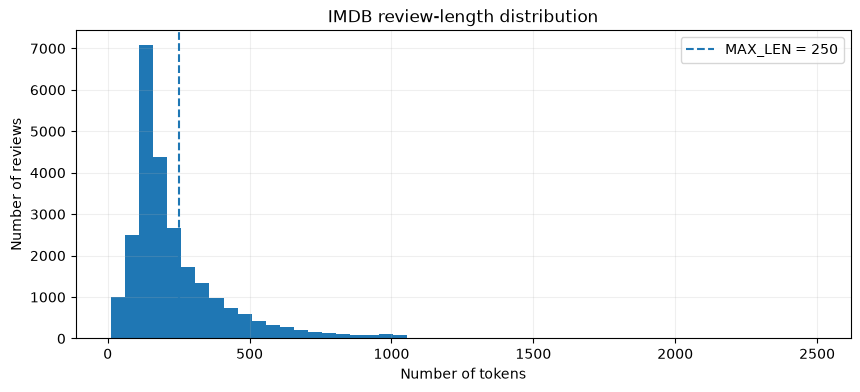

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

label_counts = pd.Series(y_train).value_counts().sort_index()
label_counts.index = ["Negative (0)", "Positive (1)"]
display(label_counts)

review_lengths = [len(review) for review in x_train_raw]
display(pd.Series(review_lengths).describe(
    percentiles=[0.50, 0.75, 0.90, 0.95]
))

plt.figure(figsize=(10, 4))
plt.hist(review_lengths, bins=50)
plt.axvline(MAX_LEN, linestyle="--", label=f"MAX_LEN = {MAX_LEN}")
plt.title("IMDB review-length distribution")
plt.xlabel("Number of tokens")
plt.ylabel("Number of reviews")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 5.4 Padding and truncation

We make every review exactly 250 positions long.

- `maxlen=MAX_LEN`: final length is 250.
- `padding="pre"`: zeros are added at the beginning of short reviews.
- `truncating="post"`: tokens at the end of long reviews are removed.
- `value=0`: zero is the padding token.

Example with a maximum length of 6:

```text
Original:          [12, 15, 20]
After pre-padding: [0, 0, 0, 12, 15, 20]
```

Padding does not create words. It makes the sequence dimensions consistent. The Embedding layer's `mask_zero=True` will mark these zero positions as padding for compatible recurrent layers.

In [8]:
x_train = tf.keras.utils.pad_sequences(
    x_train_raw,
    maxlen=MAX_LEN,
    padding="pre",
    truncating="post",
    value=0
)

x_test = tf.keras.utils.pad_sequences(
    x_test_raw,
    maxlen=MAX_LEN,
    padding="pre",
    truncating="post",
    value=0
)

print("Training shape:", x_train.shape)
print("Test shape:", x_test.shape)
print("One padded review:", x_train[0][:30])

Training shape: (25000, 250)
Test shape: (25000, 250)
One padded review: [   1   11 4079   11    4 1986  745 3304  299 1206  590 3029 1042   37
   47   27 1269    2 7637   19    6 3586   15 1367 3196   17 1002  723
 1768 2887]


Expected shapes:

```text
Training: (25000, 250)
Test:     (25000, 250)
```

The input is currently 2D: `(samples, token_positions)`. After the Embedding layer, it will become 3D: `(samples, 250, 64)`.

## 5.5 Decode a review for human inspection

The model uses integer IDs, but we can reverse the IDs to inspect a review.

The IMDB dataset reserves IDs 0–3 for special tokens. Ordinary word IDs are offset by 3 from the dictionary returned by `get_word_index()`.

This helper is only for inspection; it is not part of model training.

In [9]:
word_index = tf.keras.datasets.imdb.get_word_index()

index_word = {
    index + 3: word
    for word, index in word_index.items()
}

index_word.update({
    0: "<PAD>",
    1: "<START>",
    2: "<UNK>",
    3: "<UNUSED>"
})

def decode_review(token_ids):
    words = []
    for token_id in token_ids:
        token_id = int(token_id)
        if token_id != 0:
            words.append(index_word.get(token_id, "<UNK>"))
    return " ".join(words)

print(decode_review(x_train[0])[:1000])
print("Actual sentiment:", "Positive" if y_train[0] == 1 else "Negative")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
<START> in panic in the streets richard widmark plays u s navy doctor who has his week <UNK> interrupted with a corpse that contains plague as cop paul douglas properly points out the guy died from two bullets in the chest that's not the issue here the two of them become unwilling partners in an effort to find the killers and anyone else exposed to the disease br br as was pointed out by any number of people for some reason director <UNK> kazan did not bother to cast the small parts with anyone that sounds like they're from <UNK> having been to new orleans where the story takes place i can personally <UNK> to that richard widmark and his wife barbara <UNK> <UNK> can be <UNK> because as a navy doctor he could be assigned there but for those that are natives it doesn't work br br but with plague out there and the news being kept a secret the new orleans <UNK> starts a <UNK> of the city's underworld the dead guy came off a ship from europe 

## 5.6 Create fit and validation partitions

The original training set has 25,000 reviews. We reserve 20% for validation.

- Fit partition: used to update model weights.
- Validation partition: used to monitor generalization and early stopping.
- Official test partition: kept separate until final evaluation.

`stratify=y_train` keeps the positive/negative proportions approximately consistent across the fit and validation partitions.

In [ ]:
from sklearn.model_selection import train_test_split

x_fit, x_val, y_fit, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train
)

print("Fit reviews:", x_fit.shape[0])
print("Validation reviews:", x_val.shape[0])
print("Official test reviews:", x_test.shape[0])

# Part 6 – Build the three models

All models use this broad pipeline:

```text
250 token IDs
      ↓
Embedding (64 values per token)
      ↓
Recurrent layer
      ↓
Dense (32, ReLU)
      ↓
Dropout
      ↓
Dense (1, sigmoid)
      ↓
Positive sentiment probability
```

We change the recurrent layer while keeping the surrounding pipeline comparable.

The sigmoid output is a number between 0 and 1:
- ≥ 0.5 → positive
- < 0.5 → negative

Binary cross-entropy is appropriate because this is a two-class classification task.

## 6.1 Common compilation and early stopping

All models use Adam with the same learning rate, binary cross-entropy loss and accuracy metric.

Early stopping monitors validation loss. If it does not improve for two consecutive epochs, training stops and the weights from the best validation-loss epoch are restored.

In [ ]:
def compile_classifier(model):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


def make_early_stopping():
    return tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    )

## 6.2 Model A – SimpleRNN

The Embedding layer maps each token ID to a 64-dimensional vector.

SimpleRNN reads the embedded sequence from left to right and updates its hidden state at each time step. With the default `return_sequences=False`, it returns the final sequence representation.

That 64-value representation is passed to the Dense classification head.

In [ ]:
def build_simple_rnn():
    inputs = tf.keras.Input(shape=(MAX_LEN,), dtype="int32")

    x = tf.keras.layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True,
        name="word_embedding"
    )(inputs)

    x = tf.keras.layers.SimpleRNN(
        RNN_UNITS,
        activation="tanh",
        dropout=0.2,
        name="simple_rnn"
    )(x)

    x = tf.keras.layers.Dense(32, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

    model = tf.keras.Model(inputs, outputs, name="SimpleRNN_sentiment")
    return compile_classifier(model)


rnn_model = build_simple_rnn()
rnn_model.summary()

## 6.3 Model B – LSTM

The broad architecture stays the same. We replace SimpleRNN with LSTM.

LSTM maintains a hidden state and a cell state. Its forget, input and output gates regulate information flow through the sequence.

The final 64-value LSTM representation is passed to the same Dense classification head.

In [ ]:
def build_lstm():
    inputs = tf.keras.Input(shape=(MAX_LEN,), dtype="int32")

    x = tf.keras.layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True,
        name="word_embedding"
    )(inputs)

    x = tf.keras.layers.LSTM(
        RNN_UNITS,
        activation="tanh",
        dropout=0.2,
        name="lstm"
    )(x)

    x = tf.keras.layers.Dense(32, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

    model = tf.keras.Model(inputs, outputs, name="LSTM_sentiment")
    return compile_classifier(model)


lstm_model = build_lstm()
lstm_model.summary()

## 6.4 Model C – Bidirectional LSTM

The Bidirectional wrapper runs two independent LSTMs:
- Forward LSTM reads the sequence from beginning to end.
- Backward LSTM reads it from end to beginning.

`merge_mode="concat"` joins their final representations.

Each direction has 64 units, so the concatenated representation has 128 values:

```text
Forward:      64 values
Backward:     64 values
Concatenated: 128 values
```

The Dense layer therefore receives 128 features rather than 64.

This can help when the complete review is available at prediction time, because the representation can use context from both directions. It does not guarantee better results.

In [ ]:
def build_bidirectional_lstm():
    inputs = tf.keras.Input(shape=(MAX_LEN,), dtype="int32")

    x = tf.keras.layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True,
        name="word_embedding"
    )(inputs)

    x = tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(
            RNN_UNITS,
            activation="tanh",
            dropout=0.2
        ),
        merge_mode="concat",
        name="bidirectional_lstm"
    )(x)

    x = tf.keras.layers.Dense(32, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

    model = tf.keras.Model(inputs, outputs, name="BiLSTM_sentiment")
    return compile_classifier(model)


bilstm_model = build_bidirectional_lstm()
bilstm_model.summary()

# Part 7 – Train the three models

We use the same fit data, validation data, batch size, maximum epochs and early-stopping rule.

The `History` object stores the training and validation loss/accuracy after each epoch. We also record elapsed training time for comparison.

In [ ]:
import time

def train_model(model, model_name):
    start_time = time.perf_counter()

    history = model.fit(
        x_fit,
        y_fit,
        validation_data=(x_val, y_val),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[make_early_stopping()],
        verbose=1
    )

    elapsed = time.perf_counter() - start_time
    print(f"{model_name} training time: {elapsed:.2f} seconds")
    return history, elapsed


rnn_history, rnn_training_seconds = train_model(rnn_model, "SimpleRNN")

In [ ]:
lstm_history, lstm_training_seconds = train_model(lstm_model, "LSTM")

In [ ]:
bilstm_history, bilstm_training_seconds = train_model(
    bilstm_model, "Bidirectional LSTM"
)

# Part 8 – Compare learning curves

The History object stores:
- `loss`: loss on fit data.
- `accuracy`: accuracy on fit data.
- `val_loss`: loss on validation data.
- `val_accuracy`: accuracy on validation data.

Higher validation accuracy is generally better. Lower validation loss is generally better.

If training performance keeps improving while validation performance deteriorates, that can indicate overfitting.

In [ ]:
histories = {
    "SimpleRNN": rnn_history,
    "LSTM": lstm_history,
    "Bidirectional LSTM": bilstm_history
}

plt.figure(figsize=(11, 5))
for name, history in histories.items():
    plt.plot(history.history["val_accuracy"], marker="o", label=name)

plt.title("Validation accuracy comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [ ]:
plt.figure(figsize=(11, 5))
for name, history in histories.items():
    plt.plot(history.history["val_loss"], marker="o", label=name)

plt.title("Validation loss comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation binary cross-entropy")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

# Part 9 – Evaluate on the official test set

Only now do we evaluate on the official test set. It has not been used to update weights or select the best epoch.

The model outputs a positive-class probability. We use 0.5 as the classification threshold.

Metrics:
- **Accuracy:** proportion of all reviews classified correctly.
- **Precision:** among reviews predicted positive, proportion actually positive.
- **Recall:** among genuinely positive reviews, proportion identified.
- **F1:** harmonic mean of precision and recall.

Read the metrics together; no single metric tells the whole story.

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

def evaluate_classifier(model, X, y, model_name):
    probabilities = model.predict(
        X, batch_size=256, verbose=0
    ).ravel()

    predictions = (probabilities >= 0.5).astype("int32")

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(y, predictions, zero_division=0),
        "Recall": recall_score(y, predictions, zero_division=0),
        "F1": f1_score(y, predictions, zero_division=0),
        "probabilities": probabilities,
        "predictions": predictions
    }


rnn_result = evaluate_classifier(rnn_model, x_test, y_test, "SimpleRNN")
lstm_result = evaluate_classifier(lstm_model, x_test, y_test, "LSTM")
bilstm_result = evaluate_classifier(
    bilstm_model, x_test, y_test, "Bidirectional LSTM"
)

results = [rnn_result, lstm_result, bilstm_result]

In [ ]:
training_times = {
    "SimpleRNN": rnn_training_seconds,
    "LSTM": lstm_training_seconds,
    "Bidirectional LSTM": bilstm_training_seconds
}

comparison_rows = []
for result in results:
    comparison_rows.append({
        "Model": result["Model"],
        "Accuracy": result["Accuracy"],
        "Precision": result["Precision"],
        "Recall": result["Recall"],
        "F1": result["F1"],
        "Training time (seconds)": training_times[result["Model"]]
    })

comparison = pd.DataFrame(comparison_rows)
display(comparison.sort_values("F1", ascending=False).reset_index(drop=True))

# Part 10 – Confusion matrices

| Actual / Predicted | Predicted negative | Predicted positive |
|---|---:|---:|
| Actual negative | True Negative | False Positive |
| Actual positive | False Negative | True Positive |

- True Negative: negative review correctly predicted negative.
- False Positive: negative review incorrectly predicted positive.
- False Negative: positive review incorrectly predicted negative.
- True Positive: positive review correctly predicted positive.

The diagonal cells are correct predictions; off-diagonal cells are mistakes.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, result in zip(axes, results):
    cm = confusion_matrix(y_test, result["predictions"])
    ax.imshow(cm)
    ax.set_title(result["Model"])
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    ax.set_xticks([0, 1], labels=["Negative", "Positive"])
    ax.set_yticks([0, 1], labels=["Negative", "Positive"])

    for (row, col), value in np.ndenumerate(cm):
        ax.text(col, row, str(value), ha="center", va="center")

plt.tight_layout()
plt.show()

# Part 11 – Inspect individual review predictions

Aggregate metrics summarize performance. Individual examples help us see where models agree or disagree.

We decode selected test reviews, show their actual sentiment, and display each model's positive probability and predicted label.

In [ ]:
def inspect_reviews(indices):
    rows = []

    for idx in indices:
        row = {
            "Review excerpt": decode_review(x_test[idx])[:350] + "...",
            "Actual sentiment": "Positive" if y_test[idx] == 1 else "Negative"
        }

        for result in results:
            name = result["Model"]
            probability = float(result["probabilities"][idx])
            prediction = int(result["predictions"][idx])

            row[f"{name} P(positive)"] = round(probability, 3)
            row[f"{name} prediction"] = (
                "Positive" if prediction == 1 else "Negative"
            )

        rows.append(row)

    return pd.DataFrame(rows)


display(inspect_reviews([0, 1, 2, 10, 25]))

# Part 12 – Discussion questions

Use the actual results from your run. Do not assume one architecture must win.

1. Which model achieved the highest test accuracy?
2. Which achieved the highest F1 score?
3. Did LSTM improve over SimpleRNN in this run?
4. Did BiLSTM improve over the unidirectional LSTM?
5. Which took the longest to train?
6. Do the validation curves and test metrics tell a consistent story?
7. Find a review where the models disagree. What is interesting about its wording or context?
8. Why might processing a complete review in both directions help sentiment classification?
9. Why might BiLSTM be unsuitable for some real-time prediction problems?

### Important limitation of BiLSTM

Sentiment classification is performed after the complete review is available, so a backward pass over the review is possible.

For next-word generation or forecasting, future target information is unknown. A model must not use information from a future period that would not be available at prediction time.

A backward pass over a fully observed historical input window is not automatically leakage. The important question is whether the model receives information from the period it is supposed to predict.

# Final recap

| Concept | Purpose |
|---|---|
| Tokenization | Breaks text into tokens |
| Token IDs | Assigns integer identifiers |
| One-hot | Sparse binary representation |
| BoW | Represents documents using term counts |
| TF-IDF | Weights terms using term/document frequency |
| Word2Vec | Learns vectors using CBOW or Skip-gram |
| GloVe | Learns vectors from global co-occurrence statistics |
| Embedding layer | Maps token IDs to trainable dense vectors |
| SimpleRNN | Processes a sequence through recurrent hidden state |
| LSTM | Uses gates and cell state to regulate information |
| BiLSTM | Processes a sequence in forward and backward directions |

## The complete progression

```text
Text
 ↓
Tokens
 ↓
Token IDs
 ↓
Embedding vectors
 ↓
Sequence model
 ↓
Classification
```

**Key takeaway:** The Embedding layer does not replace the RNN or LSTM. It provides a dense vector for each token. The recurrent layer processes those vectors in sequence and learns patterns useful for the task.

### Instructor note
This notebook uses an Embedding layer trained from scratch for the IMDB sentiment task. Word2Vec and GloVe are explained conceptually, not trained here. The simple Keras IMDB dataset has its own token-ID conventions; for production inference, use a tokenizer/preprocessing pipeline that exactly matches training.